In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Đọc file

In [3]:
import json
from pathlib import Path

path = Path(r"D:\PYTHON\Data mining\VN-IT-Job-Mining\crawlers\sources\topdev\topdev_jobs.json")

# 1. Đọc nội dung file thô
with open(path, "r", encoding="utf-8") as f:
    raw_data = json.load(f)

# 2. Kiểm tra kiểu dữ liệu gốc
print(f"Kiểu dữ liệu gốc: {type(raw_data)}")

# Trường hợp A: Root là dict và data nằm bên trong key con (ví dụ: 'data', 'jobs', 'items')
if isinstance(raw_data, dict):
    print("Các keys trong file:", list(raw_data.keys()))
    
    # Giả sử jobs nằm trong key 'data' hoặc 'items'
    target_data = raw_data.get("data") or raw_data.get("jobs") or raw_data.get("items") or raw_data
    df = pd.json_normalize(target_data)

# Trường hợp B: Root là một list các job
elif isinstance(raw_data, list):
    # Lọc bỏ các phần tử không phải dict (nếu crawl bị lẫn null hoặc chuỗi rỗng)
    clean_data = [item for item in raw_data if isinstance(item, dict)]
    df = pd.json_normalize(clean_data)

print(f"Đọc thành công {len(df)} dòng dữ liệu.")
print(df.head())

Kiểu dữ liệu gốc: <class 'dict'>
Các keys trong file: ['metadata', 'jobs']
Đọc thành công 2819 dòng dữ liệu.
  category_ids  listing_response.id  \
0          [1]              2138248   
1          [1]              2138779   
2          [1]              2138328   
3          [1]              2138340   
4          [1]              2138343   

                            listing_response.title  \
0  C/C++ Software Developer – Telecom (All Levels)   
1        [2026_KTUD]_Chuyên viên Kiểm thử ứng dụng   
2                                 Business Analyst   
3                                  PROJECT MANAGER   
4                                   UI/UX Designer   

   listing_response.is_content_image  \
0                              False   
1                              False   
2                              False   
3                              False   
4                              False   

   listing_response.is_content_image_enabled  listing_response.owned_id  \
0              

In [4]:
df.head(10)

,category_ids,listing_response.id,listing_response.title,listing_response.is_content_image,listing_response.is_content_image_enabled,listing_response.owned_id,listing_response.company.id,listing_response.company.display_name,listing_response.company.image_logo,listing_response.company.slug,...,detail_response.is_blacklisted,detail_response.recalled_at,detail_response.is_remove_cv,detail_response.is_viewed,detail_response.requirements_arr,detail_response.responsibilities_original,detail_response.requirements_original,detail_response.benefits_original,detail_response.recruitment_process_original,detail_response.promotions
0,[1],2138248,C/C++ Software Developer – Telecom (All Levels),False,False,97173,97173,RemotePeople,https://assets.saramin.vn/images/2026/10/13/Sa...,remotepeople,...,False,None,False,False,None,"Design, develop & maintain high-performance C/...",Strong C/C++ skills Embedded / Telecom softwar...,"[{'icon': None, 'value': 'Salary: 10,000,000 V...",None,None
1,[1],2138779,[2026_KTUD]_Chuyên viên Kiểm thử ứng dụng,False,False,85897,85897,Vietcombank,https://assets.saramin.vn/images/2023/02/21/To...,vietcombank,...,False,None,False,False,None,Thực hiện các công tác kiểm thử: Xây dựng kế h...,1. Trình độ: Trình độ chuyên môn: Tốt nghiệp Đ...,"[{'icon': None, 'value': None}]",None,None
2,[1],2138328,Business Analyst,False,False,97175,97175,CÔNG TY CỔ PHẦN GLOBAL TECHNOLOGY SOLUTIONS VI...,https://assets.saramin.vn/images/2026/10/13/Sa...,cong-ty-co-phan-global-technology-solutions-vi...,...,False,None,False,False,None,Tiếp nhận yêu cầu sản phẩm/dịch vụ cho các sản...,Có trên 3 năm kinh nghiệm làm việc tại vị trí ...,"[{'icon': None, 'value': 'Mức lương cạnh tranh...",None,None
3,[1],2138340,PROJECT MANAGER,False,False,78272,78272,DTN E-COMMERCE SOFTWARE COMPANY LIMITED,https://assets.saramin.vn/images/2025/02/05/To...,dtn-e-commerce-software-company-limited,...,False,None,False,False,None,"Quản lý và theo dõi dự án e-commerce, đảm bảo ...",Kỹ năng & trình độ của bạn Có ít nhất từ 3 năm...,"[{'icon': None, 'value': 'Mức lương từ 20tr - ...",None,None
4,[1],2138343,UI/UX Designer,False,False,96940,96940,CÔNG TY TNHH CÔNG NGHỆ RONTECH,https://assets.saramin.vn/images/2026/07/06/To...,cong-ty-tnhh-cong-nghe-rontech,...,False,None,False,False,None,Thiết kế UI/UX cho MDM Admin Console: dashboar...,"Học vấn: Cử nhân Thiết kế Đồ họa, Thiết kế Tươ...","[{'icon': None, 'value': 'Đóng BHXH – BHYT – B...",None,None
5,[1],2138283,Full Stack Developer (NodeJS/ReactJS),False,False,97174,97174,CÔNG TY TNHH SOFTFLEX LLC,https://assets.saramin.vn/images/2026/10/13/Sa...,cong-ty-tnhh-softflex-llc,...,False,None,False,False,None,"Duties & Responsibilities Design, develop, and...",4+ years of experience with backend developmen...,"[{'icon': None, 'value': 'Attractive salary pa...",None,None
6,[1],2136432,Data Engineer (Big Data / Lakehouse),False,False,86167,86167,F88 Business JSC,https://assets.saramin.vn/images/2021/01/22/F8...,f88-business-jsc,...,False,None,False,False,None,"Xây dựng và tối ưu các pipeline ETL/ELT, đưa d...",Có 2–4 năm kinh nghiệm Data Engineering hoặc p...,"[{'icon': None, 'value': 'Chế độ chính sách: L...",None,None
7,[1],2134039,[Hanoi] Senior Automation & AI System Engineer,False,False,94383,94383,ZEDER VIỆT NAM,https://assets.saramin.vn/images/2023/10/24/To...,zeder-viet-nam,...,False,None,False,False,None,Scoping and requirements Meet with department ...,Excellent written and spoken English is essent...,"[{'icon': None, 'value': '13 Months of Salary ...",None,None
8,[1],2133063,Fullstack AI Engineer,False,False,97102,97102,CÔNG TY CỔ PHẦN CÔNG NGHỆ BOOKINGCARE,https://assets.saramin.vn/images/2026/09/15/Sa...,cong-ty-co-phan-cong-nghe-bookingcare,...,False,None,False,False,None,Phát triển sản phẩm và các tính năng sản phẩm ...,Bạn phù hợp nếu Có từ 3-5 năm kinh nghiệm phát...,"[{'icon': None, 'value': 'Mức lương gross: 30-...",None,None
9,[1],2132677,PRODUCT MANAGER – IT/CYBERSECURITY VENDOR MANA...,False,False,

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2819 entries, 0 to 2818
Data columns (total 69 columns):
 #   Column                                           Non-Null Count  Dtype 
---  ------                                           --------------  ----- 
 0   category_ids                                     2819 non-null   object
 1   listing_response.id                              2819 non-null   int64 
 2   listing_response.title                           2819 non-null   object
 3   listing_response.is_content_image                2819 non-null   bool  
 4   listing_response.is_content_image_enabled        2819 non-null   bool  
 5   listing_response.owned_id                        2819 non-null   int64 
 6   listing_response.company.id                      2819 non-null   int64 
 7   listing_response.company.display_name            2819 non-null   object
 8   listing_response.company.image_logo              2819 non-null   object
 9   listing_response.company.slug            

In [6]:
df.describe(include='all')

,category_ids,listing_response.id,listing_response.title,listing_response.is_content_image,listing_response.is_content_image_enabled,listing_response.owned_id,listing_response.company.id,listing_response.company.display_name,listing_response.company.image_logo,listing_response.company.slug,...,detail_response.is_blacklisted,detail_response.recalled_at,detail_response.is_remove_cv,detail_response.is_viewed,detail_response.requirements_arr,detail_response.responsibilities_original,detail_response.requirements_original,detail_response.benefits_original,detail_response.recruitment_process_original,detail_response.promotions
count,2819,2.819000e+03,2819,2819,2819,2819.000000,2819.000000,2819,2819,2819,...,2819,0,2819,2819,1,2817,2813,2819,0,0
unique,6,NaN,2694,1,1,NaN,NaN,215,215,215,...,1,0,1,1,1,2355,2381,1693,0,0
top,[14],NaN,Kỹ Sư Cơ Khí,False,False,NaN,NaN,Ngân hàng TMCP Việt Nam Thịnh Vượng (VPBank),https://assets.saramin.vn/images/2023/06/27/To...,ngan-hang-tmcp-viet-nam-thinh-vuong-vpbank,...,False,NaN,False,False,"[{'name': 'Development Tools', 'icon': 'https:...","Chủ động tìm kiếm khách hàng mới, tư vấn giới ...",1. Trình độ Học vấn: Tốt nghiệp cao đẳng trở l...,"[{'icon': None, 'value': None}]",NaN,NaN
freq,1638,NaN,5,2819,2819,NaN,NaN,437,437,437,...,2819,NaN,2819,2819,1,22,19,312,NaN,NaN
mean,NaN,2.137630e+06,NaN,NaN,NaN,89077.291947,89077.291947,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,1.007560e+03,NaN,NaN,NaN,8856.654375,8856.654375,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,2.132204e+06,NaN,NaN,NaN,52170.000000,52170.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,2.136966e+06,NaN,NaN,NaN,83868.000000,83868.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,2.137703e+06,NaN,NaN,NaN,92215.000000,92215.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,2.138414e+06,NaN,NaN,NaN,96274.000000,96274.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### null

In [7]:
# 1. Tính toán thống kê null
null_df = pd.DataFrame({
    'Số lượng Null': df.isnull().sum(),
    'Tỷ lệ Null (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Số lượng Non-Null': df.notnull().sum(),
    'Kiểu dữ liệu': df.dtypes
})

# 2. Lọc các cột có null và sắp xếp giảm dần
null_table = null_df[null_df['Số lượng Null'] > 0].sort_values(by='Số lượng Null', ascending=False)

# 3. Hiển thị dạng bảng có màu biểu thị độ nghiêm trọng (trên Jupyter Notebook)
null_table.style.bar(subset=['Tỷ lệ Null (%)'], color='#ff6b6b', vmin=0, vmax=100) \
                .format({'Tỷ lệ Null (%)': '{:.2f}%'})

,Số lượng Null,Tỷ lệ Null (%),Số lượng Non-Null,Kiểu dữ liệu
listing_response.recalled_at,2819,100.00%,0,object
listing_response.promotions,2819,100.00%,0,object
detail_response.recruitment_process_original,2819,100.00%,0,object
detail_response.recalled_at,2819,100.00%,0,object
detail_response.promotions,2819,100.00%,0,object
detail_response.requirements_arr,2818,99.96%,1,object
detail_response.content,1959,69.49%,860,object
listing_response.skills_str,1578,55.98%,1241,object
listing_response.skills_arr,1578,55.98%,1241,object
detail_response.requirements_original,6,0.21%,2813,object


##### Biểu đồ null

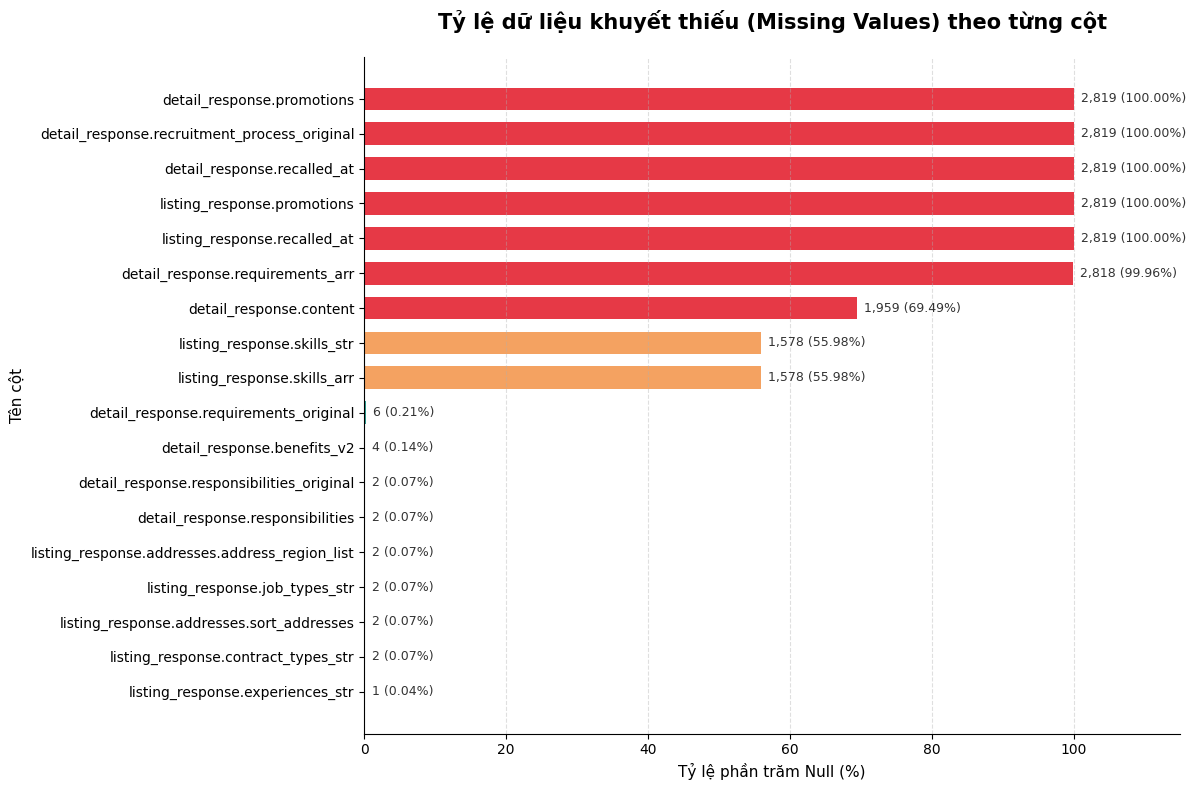

In [8]:
# 1. Tính toán thống kê null
null_counts = df.isnull().sum()
null_percent = (null_counts / len(df)) * 100

null_df = pd.DataFrame({
    'Column': null_counts.index,
    'Null_Count': null_counts.values,
    'Null_Percent': null_percent.values
})

# Lọc các cột có null và sắp xếp tăng dần để vẽ thanh ngang
null_df = null_df[null_df['Null_Count'] > 0].sort_values(by='Null_Percent', ascending=True)

# 2. Thiết lập màu sắc theo mức độ thiếu
def get_color(pct):
    if pct >= 60:
        return '#e63946'  # Đỏ cảnh báo cao
    elif pct >= 20:
        return '#f4a261'  # Cam cảnh báo trung bình
    else:
        return '#2a9d8f'  # Xanh (thiếu ít)

colors = [get_color(p) for p in null_df['Null_Percent']]

# 3. Vẽ biểu đồ
plt.figure(figsize=(12, 8))
bars = plt.barh(null_df['Column'], null_df['Null_Percent'], color=colors, height=0.65)

# Ghi chú thích số lượng và % trực tiếp lên đầu mỗi cột
for bar, count, pct in zip(bars, null_df['Null_Count'], null_df['Null_Percent']):
    plt.text(
        bar.get_width() + 1, 
        bar.get_y() + bar.get_height() / 2, 
        f"{count:,} ({pct:.2f}%)", 
        va='center', 
        ha='left', 
        fontsize=9, 
        color='#333333',
        fontweight='medium'
    )

plt.title('Tỷ lệ dữ liệu khuyết thiếu (Missing Values) theo từng cột', fontsize=15, pad=20, fontweight='bold')
plt.xlabel('Tỷ lệ phần trăm Null (%)', fontsize=11)
plt.ylabel('Tên cột', fontsize=11)
plt.xlim(0, 115)  # Để khoảng trống hiển thị nhãn số
plt.grid(axis='x', linestyle='--', alpha=0.4)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

### Outliner

#### salary

In [9]:
# 1. Lọc tất cả các cột có chứa chữ 'salary'
salary_cols = [c for c in df.columns if 'salary' in c.lower()]

# 2. Tạo DataFrame riêng
df_salary = df[salary_cols].copy()

# 3. Kiểm tra các cột đã lấy
print(f"Dòng: {df_salary.shape[0]}, Cột: {df_salary.shape[1]}")
print(df_salary.columns.tolist())
display(df_salary.head())

Dòng: 2819, Cột: 13
['listing_response.salary.min_estimate', 'listing_response.salary.currency_estimate', 'listing_response.salary.unit', 'listing_response.salary.min', 'listing_response.salary.max', 'listing_response.salary.min_filter', 'listing_response.salary.is_negotiable', 'listing_response.salary.currency', 'listing_response.salary.max_filter', 'listing_response.salary.value', 'listing_response.salary.max_estimate', 'listing_response.is_salary_visible', 'detail_response.is_salary_visible']


,listing_response.salary.min_estimate,listing_response.salary.currency_estimate,listing_response.salary.unit,listing_response.salary.min,listing_response.salary.max,listing_response.salary.min_filter,listing_response.salary.is_negotiable,listing_response.salary.currency,listing_response.salary.max_filter,listing_response.salary.value,listing_response.salary.max_estimate,listing_response.is_salary_visible,detail_response.is_salary_visible
0,0,VND,MONTH,10000000,60000000,10000000,0,VND,60000000,10.000.000 VND to 60.000.000 VND,0,True,True
1,0,VND,MONTH,0,0,0,1,VND,0,Thương lượng,0,True,True
2,0,VND,MONTH,0,35000000,0,0,VND,35000000,Lên tới 35.000.000 VND,0,True,True
3,0,VND,MONTH,20000000,40000000,20000000,0,VND,40000000,20.000.000 VND to 40.000.000 VND,0,True,True
4,0,VND,MONTH,18000000,0,18000000,0,VND,0,Từ 18.000.000 VND,0,True,True


In [37]:
# 1. Tính toán thống kê null
null_salary = pd.DataFrame({
    'Số lượng Null': df_salary.isnull().sum(),
    'Tỷ lệ Null (%)': (df_salary.isnull().sum() / len(df_salary) * 100).round(2),
    'Số lượng Non-Null': df_salary.notnull().sum(),
    'Kiểu dữ liệu': df_salary.dtypes
})

# 2. Lọc các cột có null và sắp xếp giảm dần
null_table = null_salary[null_salary['Số lượng Null'] > 0].sort_values(by='Số lượng Null', ascending=False)

# 3. Hiển thị dạng bảng có màu biểu thị độ nghiêm trọng (trên Jupyter Notebook)
null_table.style.bar(subset=['Tỷ lệ Null (%)'], color='#ff6b6b', vmin=0, vmax=100) \
                .format({'Tỷ lệ Null (%)': '{:.2f}%'})

,Số lượng Null,Tỷ lệ Null (%),Số lượng Non-Null,Kiểu dữ liệu


In [10]:
cols = ['listing_response.salary.currency', 'listing_response.salary.unit']

for col in cols:
    print(f"\n--- Phân phối giá trị của cột: {col} ---")
    print(df[col].value_counts(dropna=False))


--- Phân phối giá trị của cột: listing_response.salary.currency ---
listing_response.salary.currency
VND    2686
USD     133
Name: count, dtype: int64

--- Phân phối giá trị của cột: listing_response.salary.unit ---
listing_response.salary.unit
MONTH    2819
Name: count, dtype: int64


##### Biểu đồ tròn vnd & usd

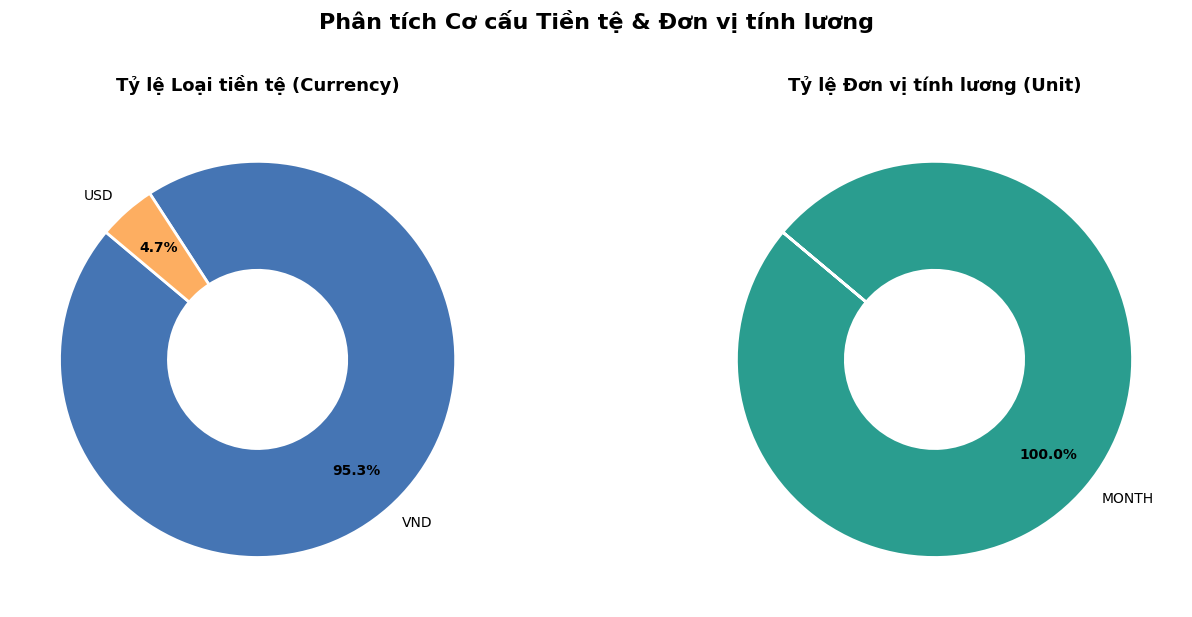

In [11]:
# 1. Chuẩn bị dữ liệu và xử lý giá trị khuyết thiếu (nếu có)
col_currency = "listing_response.salary.currency"
col_unit = "listing_response.salary.unit"

currency_counts = (
    df_salary[col_currency].fillna("Chưa xác định").astype(str).value_counts()
)
unit_counts = df_salary[col_unit].fillna("Chưa xác định").astype(str).value_counts()

# 2. Thiết lập bảng màu và bố cục 2 biểu đồ cạnh nhau
colors_currency = ["#4575b4", "#fdae61", "#d73027", "#abd9e9"]
colors_unit = ["#2a9d8f", "#e76f51", "#f4a261", "#e9c46a"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Biểu đồ 1: Phân bố Loại tiền tệ (Currency) ---
wedges1, texts1, autotexts1 = axes[0].pie(
    currency_counts.values,
    labels=currency_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    pctdistance=0.75,
    colors=colors_currency[: len(currency_counts)],
    wedgeprops=dict(width=0.55, edgecolor="white", linewidth=2),  # Kiểu Donut
)
for autotext in autotexts1:
    autotext.set_fontweight("bold")
    autotext.set_color("black")
axes[0].set_title(
    "Tỷ lệ Loại tiền tệ (Currency)", fontsize=13, fontweight="bold", pad=15
)

# --- Biểu đồ 2: Phân bố Đơn vị tính lương (Unit) ---
wedges2, texts2, autotexts2 = axes[1].pie(
    unit_counts.values,
    labels=unit_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    pctdistance=0.75,
    colors=colors_unit[: len(unit_counts)],
    wedgeprops=dict(width=0.55, edgecolor="white", linewidth=2),
)
for autotext in autotexts2:
    autotext.set_fontweight("bold")
    autotext.set_color("black")
axes[1].set_title(
    "Tỷ lệ Đơn vị tính lương (Unit)", fontsize=13, fontweight="bold", pad=15
)

plt.suptitle(
    "Phân tích Cơ cấu Tiền tệ & Đơn vị tính lương",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

##### Biểu đồ phân phối lương 

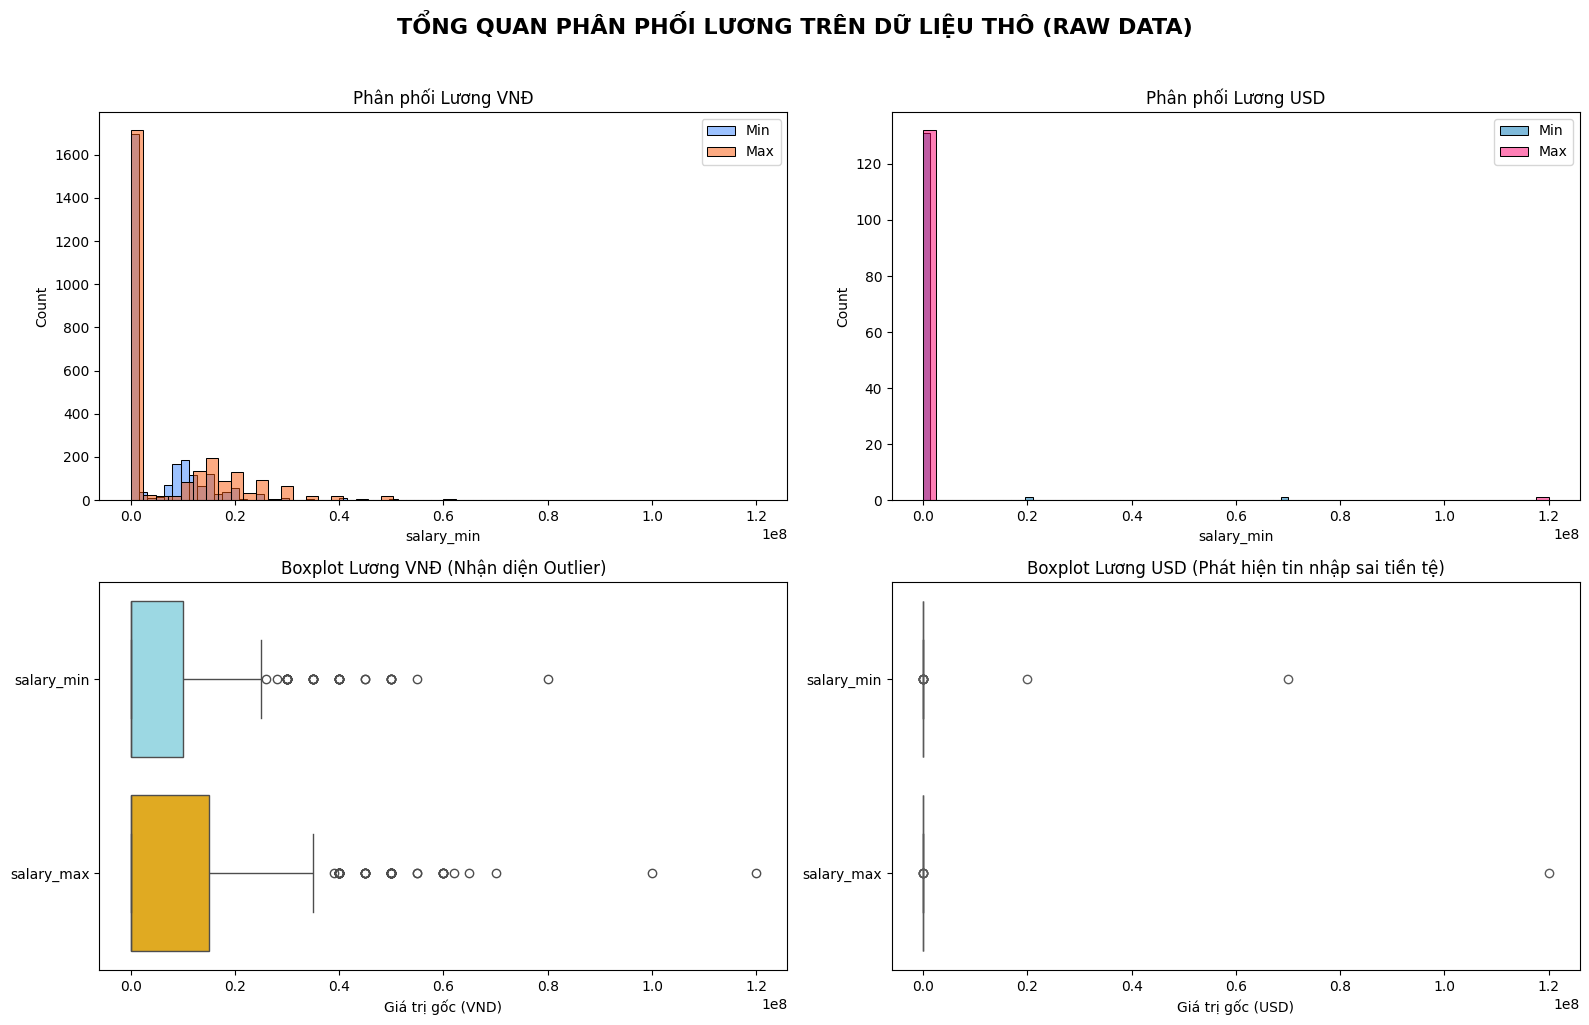

In [12]:
# 1. Trích xuất các cột cần thiết từ DataFrame thô
cols = [
    'listing_response.salary.currency',
    'listing_response.salary.min',
    'listing_response.salary.max'
]
df_raw = df_salary[cols].copy()
df_raw.columns = ['currency', 'salary_min', 'salary_max']

# Ép kiểu về số thực (chỉ ép kiểu để vẽ, không thay đổi hay lọc bất kỳ giá trị nào)
df_raw['salary_min'] = pd.to_numeric(df_raw['salary_min'], errors='coerce')
df_raw['salary_max'] = pd.to_numeric(df_raw['salary_max'], errors='coerce')

# Tách riêng tập dữ liệu theo tiền tệ
df_vnd = df_raw[df_raw['currency'] == 'VND']
df_usd = df_raw[df_raw['currency'] == 'USD']

# 2. Thiết lập lưới biểu đồ 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# --- Hàng 1: Histogram (Xem mật độ và sự tập trung của dữ liệu gốc) ---
sns.histplot(df_vnd['salary_min'], kde=False, ax=axes[0, 0], color='#3a86ff', label='Min', alpha=0.5, bins=50)
sns.histplot(df_vnd['salary_max'], kde=False, ax=axes[0, 0], color='#fb5607', label='Max', alpha=0.5, bins=50)
axes[0, 0].set_title('Phân phối Lương VNĐ', fontsize=12)
axes[0, 0].legend()

sns.histplot(df_usd['salary_min'], kde=False, ax=axes[0, 1], color='#0077b6', label='Min', alpha=0.5, bins=50)
sns.histplot(df_usd['salary_max'], kde=False, ax=axes[0, 1], color='#ff006e', label='Max', alpha=0.5, bins=50)
axes[0, 1].set_title('Phân phối Lương USD', fontsize=12)
axes[0, 1].legend()

# --- Hàng 2: Boxplot nằm ngang (Phát hiện độ lệch và lỗi nhập liệu) ---
sns.boxplot(data=df_vnd[['salary_min', 'salary_max']], orient='h', ax=axes[1, 0], palette=['#90e0ef', '#ffb703'])
axes[1, 0].set_title('Boxplot Lương VNĐ (Nhận diện Outlier)', fontsize=12)
axes[1, 0].set_xlabel('Giá trị gốc (VND)')

sns.boxplot(data=df_usd[['salary_min', 'salary_max']], orient='h', ax=axes[1, 1], palette=['#48cae4', '#ff758f'])
axes[1, 1].set_title('Boxplot Lương USD (Phát hiện tin nhập sai tiền tệ)', fontsize=12)
axes[1, 1].set_xlabel('Giá trị gốc (USD)')

plt.suptitle('TỔNG QUAN PHÂN PHỐI LƯƠNG TRÊN DỮ LIỆU THÔ (RAW DATA)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [13]:
# 1. Trích xuất 3 cột cần thiết từ dữ liệu thô
cols = [
    'listing_response.salary.currency',
    'listing_response.salary.min',
    'listing_response.salary.max'
]
df_raw = df_salary[cols].copy()
df_raw.columns = ['currency', 'salary_min', 'salary_max']

# 2. Ép kiểu dữ liệu về số nguyên/thực
df_raw['salary_min'] = pd.to_numeric(df_raw['salary_min'], errors='coerce')
df_raw['salary_max'] = pd.to_numeric(df_raw['salary_max'], errors='coerce')

# 3. Tính toán thống kê theo từng loại tiền tệ và từng cột lương
results = []
for curr in ['VND', 'USD']:
    for col, label in zip(['salary_min', 'salary_max'], ['Lương Min', 'Lương Max']):
        
        # Lọc ra các dòng đúng loại tiền tệ và có giá trị > 0 (bỏ qua lương thỏa thuận)
        s = df_raw[(df_raw['currency'] == curr) & (df_raw[col] > 0)][col].dropna()
        
        if len(s) == 0:
            continue
            
        # Tính các mốc tứ phân vị
        q1 = s.quantile(0.25)
        med = s.quantile(0.50)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        
        # Tính biên ngoại lai (Lower Bound chặn đáy ở mức 0)
        lower = max(0, q1 - 1.5 * iqr)
        upper = q3 + 1.5 * iqr
        outliers_count = ((s < q1 - 1.5 * iqr) | (s > upper)).sum()
        
        # Lưu kết quả
        results.append({
            'Tiền tệ': curr,
            'Loại': label,
            'Số tin (>0)': len(s),
            'Min': s.min(),
            'Q1 (25%)': q1,
            'Median (50%)': med,
            'Q3 (75%)': q3,
            'Max': s.max(),
            'IQR': iqr,
            'Lower Bound': lower,
            'Upper Bound': upper,
            'Outliers': outliers_count
        })

df_quartiles = pd.DataFrame(results)

# 4. Format hiển thị bảng (thêm dấu phẩy hàng nghìn và ký hiệu tiền tệ)
def format_money(val, curr):
    return f"{val:,.0f} {curr}"

money_cols = ['Min', 'Q1 (25%)', 'Median (50%)', 'Q3 (75%)', 'Max', 'IQR', 'Lower Bound', 'Upper Bound']
for idx, row in df_quartiles.iterrows():
    curr = row['Tiền tệ']
    for c in money_cols:
        df_quartiles.at[idx, c] = format_money(row[c], curr)

# Hiển thị kết quả ra bảng Markdown
display(df_quartiles.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', "#28076a"), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'td', 'props': [('padding', '8px'), ('text-align', 'right')]},
    {'selector': 'tr:nth-child(even)', 'props': [('background-color', "#190202")]},
    {'selector': 'tr:hover', 'props': [('background-color', "#171616")]},
]).set_properties(**{'border': '1px solid #ddd'})
  .set_caption("Bảng Thống kê Tứ phân vị và Outlier của Lương theo Tiền tệ")
  .hide(axis="index"))

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_18692\2906804577.py:62: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '700 VND' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_quartiles.at[idx, c] = format_money(row[c], curr)
C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_18692\2906804577.py:62: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '9,000,000 VND' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_quartiles.at[idx, c] = format_money(row[c], curr)
C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_18692\2906804577.py:62: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '12,000,000 VND' has dtype incompatible with float64, please explicitly cast to a compatible dtyp

Tiền tệ,Loại,Số tin (>0),Min,Q1 (25%),Median (50%),Q3 (75%),Max,IQR,Lower Bound,Upper Bound,Outliers
VND,Lương Min,995,700 VND,"9,000,000 VND","12,000,000 VND","15,000,000 VND","80,000,000 VND","6,000,000 VND",0 VND,"24,000,000 VND",66
VND,Lương Max,980,"1,200 VND","13,000,000 VND","17,000,000 VND","23,000,000 VND","120,000,000 VND","10,000,000 VND",0 VND,"38,000,000 VND",61
USD,Lương Min,36,450 USD,688 USD,"1,000 USD","1,200 USD","70,000,000 USD",512 USD,0 USD,"1,969 USD",8
USD,Lương Max,48,500 USD,"1,200 USD","1,750 USD","2,625 USD","120,000,000 USD","1,425 USD",0 USD,"4,762 USD",4


In [14]:
# 1. Trích xuất dữ liệu gốc và các cột định danh cần thiết
cols = [
    'listing_response.id',
    'listing_response.title',
    'listing_response.company.display_name',
    'listing_response.salary.currency',
    'listing_response.salary.min',
    'listing_response.salary.max'
]
df_raw_outliner = df[cols].copy()
df_raw_outliner.columns = ['job_id', 'title', 'company', 'currency', 'salary_min', 'salary_max']

# Ép kiểu số
df_raw_outliner['salary_min'] = pd.to_numeric(df_raw_outliner['salary_min'], errors='coerce')
df_raw_outliner['salary_max'] = pd.to_numeric(df_raw_outliner['salary_max'], errors='coerce')

outliers_list = []

# 2. Duyệt qua từng loại tiền tệ và từng cột lương để tìm Outlier
for curr in ['VND', 'USD']:
    for col in ['salary_min', 'salary_max']:
        
        # Lọc dữ liệu hợp lệ để tính phân vị (cùng tiền tệ, giá trị > 0)
        valid_data = df_raw_outliner[(df_raw_outliner['currency'] == curr) & (df_raw_outliner[col] > 0)][col].dropna()
        if len(valid_data) == 0:
            continue
            
        # Tính toán mốc IQR
        q1 = valid_data.quantile(0.25)
        q3 = valid_data.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        
        # Lọc các dòng vi phạm ranh giới
        cond_outlier = (df_raw_outliner['currency'] == curr) & (df_raw_outliner[col] > 0) & ((df_raw_outliner[col] < lower_bound) | (df_raw_outliner[col] > upper_bound))
        df_out = df_raw_outliner[cond_outlier].copy()
        
        # Ghi chú lại nguyên nhân ngoại lai
        df_out['Lý do Outlier'] = f"Vượt biên {col}"
        outliers_list.append(df_out)

# 3. Gộp danh sách các Outlier thành một DataFrame duy nhất
df_outliers = pd.concat(outliers_list, ignore_index=True)

# 4. Gộp các dòng trùng lặp (trường hợp 1 job bị outlier ở cả Min lẫn Max)
df_outliers = df_outliers.groupby(['job_id', 'title', 'company', 'currency', 'salary_min', 'salary_max'], as_index=False).agg({
    'Lý do Outlier': ' + '.join
})

# Hiển thị kết quả
print(f"Tổng số bài đăng chứa giá trị ngoại lai: {len(df_outliers)} tin")

# Xem thử top 10 bài đăng có mức lương ngoại lai cao nhất (ví dụ với USD)
display(
    df_outliers[df_outliers['currency'] == 'USD']
    .sort_values(by='salary_max', ascending=False)
    .head(10)
    .style.format({'salary_min': '{:,.0f}', 'salary_max': '{:,.0f}'})
    .hide(axis="index")
)

Tổng số bài đăng chứa giá trị ngoại lai: 99 tin


job_id,title,company,currency,salary_min,salary_max,Lý do Outlier
2138126,CEO - Chief Executive Officer,CÔNG TY TNHH ĐỊA ỐC MOSO,USD,"70,000,000","120,000,000",Vượt biên salary_min + Vượt biên salary_max
2137283,"Giám Đốc Điều Hành Nền Tảng Trực Tuyến (2,000-5,000$)",CÔNG TY CỔ PHẦN TẬP ĐOÀN APEC GROUP,USD,"2,000","5,000",Vượt biên salary_min + Vượt biên salary_max
2137310,"Giám Đốc Vườn Ươm Apec (3,000 Đến 5,000$)",CÔNG TY CỔ PHẦN TẬP ĐOÀN APEC GROUP,USD,"3,000","5,000",Vượt biên salary_min + Vượt biên salary_max
2137309,[Hot] Giám Đốc Điều Hành Công Ty Chứng Khoán Apec (CEO APS),CÔNG TY CỔ PHẦN TẬP ĐOÀN APEC GROUP,USD,"3,000","5,000",Vượt biên salary_min + Vượt biên salary_max
2138829,Trưởng phòng Thiết kế Kiểu dáng – Industrial Design Manager,CÔNG TY CỔ PHẦN TẬP ĐOÀN KAROFI,USD,"2,000","3,500",Vượt biên salary_min
2137264,Marketing Manager,CÔNG TY CỔ PHẦN TẬP ĐOÀN APEC GROUP,USD,"2,500","3,200",Vượt biên salary_min
2137311,GM Source Hotel | Tổng Quản Lý Tương Lai,CÔNG TY CỔ PHẦN TẬP ĐOÀN APEC GROUP,USD,"2,000","2,500",Vượt biên salary_min
2138539,"Expert, Retail & Small Banking Credit Risk Underwriting",Techcombank,USD,"20,000,000",0,Vượt biên salary_min


### Skill

In [15]:
cols = [
    'listing_response.skills_str',
    'listing_response.skills_arr'
]

df_raw_skills = df[cols].copy()
df_raw_skills.columns = ['skills_str', 'skills_arr']

df_raw_skills.head(5)

,skills_str,skills_arr
0,"Linux, Tester, Software Developer, C/C++, Embe...","[Linux, Tester, Software Developer, C/C++, Emb..."
1,"QA, Tester, Automation Tester","[QA, Tester, Automation Tester]"
2,"English, Agile & Scrum, API, Business Analyst,...","[English, Agile & Scrum, API, Business Analyst..."
3,"Project Manager, Agile & Scrum, Magento2, Shop...","[Project Manager, Agile & Scrum, Magento2, Sho..."
4,"Sketch, UI/UX, Figma, Adobe XD, Invision, Jira...","[Sketch, UI/UX, Figma, Adobe XD, Invision, Jir..."


In [16]:
# 1. Tính toán thống kê null
null_df_raw_skills = pd.DataFrame({
    'Số lượng Null': df_raw_skills.isnull().sum(),
    'Tỷ lệ Null (%)': (df_raw_skills.isnull().sum() / len(df_raw_skills) * 100).round(2),
    'Số lượng Non-Null': df_raw_skills.notnull().sum(),
    'Kiểu dữ liệu': df_raw_skills.dtypes
})

# 2. Lọc các cột có null và sắp xếp giảm dần
null_table = null_df_raw_skills[null_df_raw_skills['Số lượng Null'] > 0].sort_values(by='Số lượng Null', ascending=False)

# 3. Hiển thị dạng bảng có màu biểu thị độ nghiêm trọng (trên Jupyter Notebook)
null_table.style.bar(subset=['Tỷ lệ Null (%)'], color='#ff6b6b', vmin=0, vmax=100) \
                .format({'Tỷ lệ Null (%)': '{:.2f}%'})

,Số lượng Null,Tỷ lệ Null (%),Số lượng Non-Null,Kiểu dữ liệu
skills_str,1578,55.98%,1241,object
skills_arr,1578,55.98%,1241,object


##### Biểu đồ tần suất suất hiện skill

--- TOP 15 KỸ NĂNG XUẤT HIỆN NHIỀU NHẤT ---


,Kỹ năng (Skill),Số lần xuất hiện
0,Sales,261
1,Marketing,160
2,Business Development,156
3,Business/Sales,150
4,Kế toán,110
5,HR,68
6,Customer Service/Customer Support,65
7,Giảng dạy,47
8,Nhà hàng/Khách sạn/Du lịch,39
9,English,37


C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_18692\3457254696.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


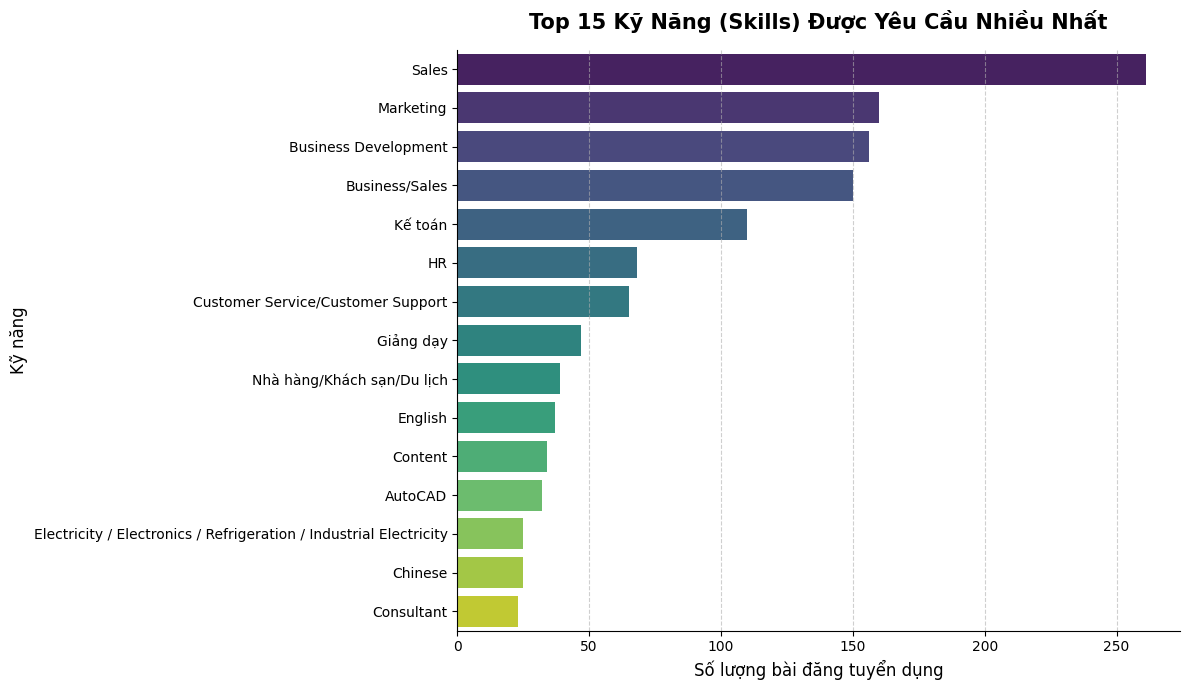

In [17]:
# 1. Trải phẳng mảng kỹ năng và đếm tần suất
# Loại bỏ các giá trị null trước khi explode để tránh lỗi
skill_series = df_raw_skills['skills_arr'].dropna().explode()

# Loại bỏ các khoảng trắng thừa ở đầu/cuối (nếu có)
skill_series = skill_series.str.strip()

# Đếm tần suất xuất hiện của từng kỹ năng
skill_counts = skill_series.value_counts()

# 2. Lấy Top 15 kỹ năng phổ biến nhất
top_15_skills = skill_counts.head(15)

# Đưa vào DataFrame và dùng display() thay cho to_markdown()
df_top_skills = top_15_skills.to_frame(name='Số lần xuất hiện').reset_index()
df_top_skills.columns = ['Kỹ năng (Skill)', 'Số lần xuất hiện']

print("--- TOP 15 KỸ NĂNG XUẤT HIỆN NHIỀU NHẤT ---")
display(df_top_skills)

# 3. Vẽ biểu đồ thanh ngang (Horizontal Bar Chart) cho trực quan
plt.figure(figsize=(12, 7))
sns.barplot(
    x=top_15_skills.values, 
    y=top_15_skills.index, 
    palette='viridis'
)

plt.title('Top 15 Kỹ Năng (Skills) Được Yêu Cầu Nhiều Nhất', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Số lượng bài đăng tuyển dụng', fontsize=12)
plt.ylabel('Kỹ năng', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
sns.despine()

plt.tight_layout()
plt.show()

In [18]:
all_skills_counts = skill_series.value_counts()

# 2. Tạo DataFrame
df_all_skills = all_skills_counts.to_frame(name='Số lần xuất hiện').reset_index()
df_all_skills.columns = ['Kỹ năng (Skill)', 'Số lần xuất hiện']

print(f"Tổng số lượng kỹ năng khác nhau: {len(df_all_skills)}")

# 3. Hiển thị toàn bộ bảng (không bị rút gọn)
with pd.option_context('display.max_rows', None):
    display(df_all_skills)

Tổng số lượng kỹ năng khác nhau: 329


,Kỹ năng (Skill),Số lần xuất hiện
0,Sales,261
1,Marketing,160
2,Business Development,156
3,Business/Sales,150
4,Kế toán,110
5,HR,68
6,Customer Service/Customer Support,65
7,Giảng dạy,47
8,Nhà hàng/Khách sạn/Du lịch,39
9,English,37


### Addresses

In [19]:
addresses_cols = [c for c in df.columns if 'address' in c.lower()]

# df dia chi
df_addresses = df[addresses_cols].copy()
df_addresses.head(5)

,listing_response.addresses.address_region_ids,listing_response.addresses.address_region_array,listing_response.addresses.collection_addresses,listing_response.addresses.full_addresses,listing_response.addresses.sort_addresses,listing_response.addresses.address_region_list
0,[01],[Thành phố Hà Nội],"[{'province': {'id': '01', 'value': 'Thành phố...","[Hà Nội, Thành phố Hà Nội]",Hà Nội,Thành phố Hà Nội
1,[01],[Thành phố Hà Nội],"[{'province': {'id': '01', 'value': 'Thành phố...","[198 Trần Quang Khải, Phường Lý Thái Tổ, Quận ...","Quận Hoàn Kiếm, Hà Nội",Thành phố Hà Nội
2,[01],[Thành phố Hà Nội],"[{'province': {'id': '01', 'value': 'Thành phố...","[Số 92, Liền kề 22, Khu đô thị Vân Canh, Xã Sơ...",Hà Nội,Thành phố Hà Nội
3,[01],[Thành phố Hà Nội],"[{'province': {'id': '01', 'value': 'Thành phố...","[B12B-02, khu đô thị Vinhomes Gardenia, đường ...","Quận Nam Từ Liêm, Hà Nội",Thành phố Hà Nội
4,[79],[Thành phố Hồ Chí Minh],"[{'id': 209746, 'ward': {'id': None, 'value': ...","[Tầng 1, Tòa nhà HSC Building, Số 162B Đường Đ...",Hồ Chí Minh,Thành phố Hồ Chí Minh


In [35]:
# 1. Tính toán thống kê null
null_address = pd.DataFrame({
    'Số lượng Null': df_addresses.isnull().sum(),
    'Tỷ lệ Null (%)': (df_addresses.isnull().sum() / len(df_addresses) * 100).round(2),
    'Số lượng Non-Null': df_addresses.notnull().sum(),
    'Kiểu dữ liệu': df_addresses.dtypes
})

# 2. Lọc các cột có null và sắp xếp giảm dần
null_table = null_address[null_address['Số lượng Null'] > 0].sort_values(by='Số lượng Null', ascending=False)

# 3. Hiển thị dạng bảng có màu biểu thị độ nghiêm trọng (trên Jupyter Notebook)
null_table.style.bar(subset=['Tỷ lệ Null (%)'], color='#ff6b6b', vmin=0, vmax=100) \
                .format({'Tỷ lệ Null (%)': '{:.2f}%'})

,Số lượng Null,Tỷ lệ Null (%),Số lượng Non-Null,Kiểu dữ liệu
listing_response.addresses.sort_addresses,2,0.07%,2817,object
listing_response.addresses.address_region_list,2,0.07%,2817,object


In [23]:
# 1. Trích xuất dữ liệu và loại bỏ các dòng rỗng (NaN)
s_regions = df_addresses['listing_response.addresses.address_region_array'].dropna()

# 2. Xử lý trải phẳng dữ liệu dạng mảng (List) và Dict (nếu có)
if not s_regions.empty:
    # Nếu dữ liệu là list (ví dụ: ['Hồ Chí Minh', 'Hà Nội'] hoặc list of dicts)
    if isinstance(s_regions.iloc[0], list):
        s_regions = s_regions.explode().dropna()
        
    # Nếu phần tử bên trong list lại là một dạng Dict (chứa id, name, ...), trích xuất giá trị text
    if not s_regions.empty and isinstance(s_regions.iloc[0], dict):
        # Thường TopDev lưu tên khu vực ở key 'name' hoặc 'value'
        s_regions = s_regions.apply(lambda x: x.get('name') if isinstance(x, dict) and 'name' in x else str(x))

# Làm sạch khoảng trắng và ép kiểu chữ
s_regions = s_regions.astype(str).str.strip()

# 3. Tính toán số lượng và tỷ lệ phần trăm
counts = s_regions.value_counts()
rates = s_regions.value_counts(normalize=True) * 100

# 4. Gộp vào DataFrame để hiển thị bảng
df_regions = pd.DataFrame({
    'Khu vực (Region)': counts.index,
    'Số lượng bài đăng': counts.values,
    'Tỷ lệ (%)': rates.values
})

# 5. In bảng kết quả bằng display() kèm style đẹp mắt
print(f"--- PHÂN BỐ KHU VỰC TUYỂN DỤNG ({'listing_response.addresses.address_region_array'}) ---")
display(
    df_regions.style
    .format({
        'Số lượng bài đăng': '{:,}', 
        'Tỷ lệ (%)': '{:.2f}%'
    })
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#4575b4'), ('color', 'white'), ('font-weight', 'bold')]},
        {'selector': 'td', 'props': [('text-align', 'left')]}
    ])
    .hide(axis="index")
)

--- PHÂN BỐ KHU VỰC TUYỂN DỤNG (listing_response.addresses.address_region_array) ---


Khu vực (Region),Số lượng bài đăng,Tỷ lệ (%)
Thành phố Hồ Chí Minh,"1,316",42.42%
Thành phố Hà Nội,"1,138",36.69%
Tỉnh Hưng Yên,66,2.13%
Thành phố Hải Phòng,62,2.00%
Thành phố Đà Nẵng,56,1.81%
Tỉnh Đồng Nai,54,1.74%
Tỉnh Tây Ninh,35,1.13%
Tỉnh Bắc Ninh,32,1.03%
Tỉnh Long An,24,0.77%
Tỉnh Quảng Ninh,24,0.77%


##### Biểu đồ phân bố tần suất suất hiện của các tỉnh thành

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_18692\2474252080.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


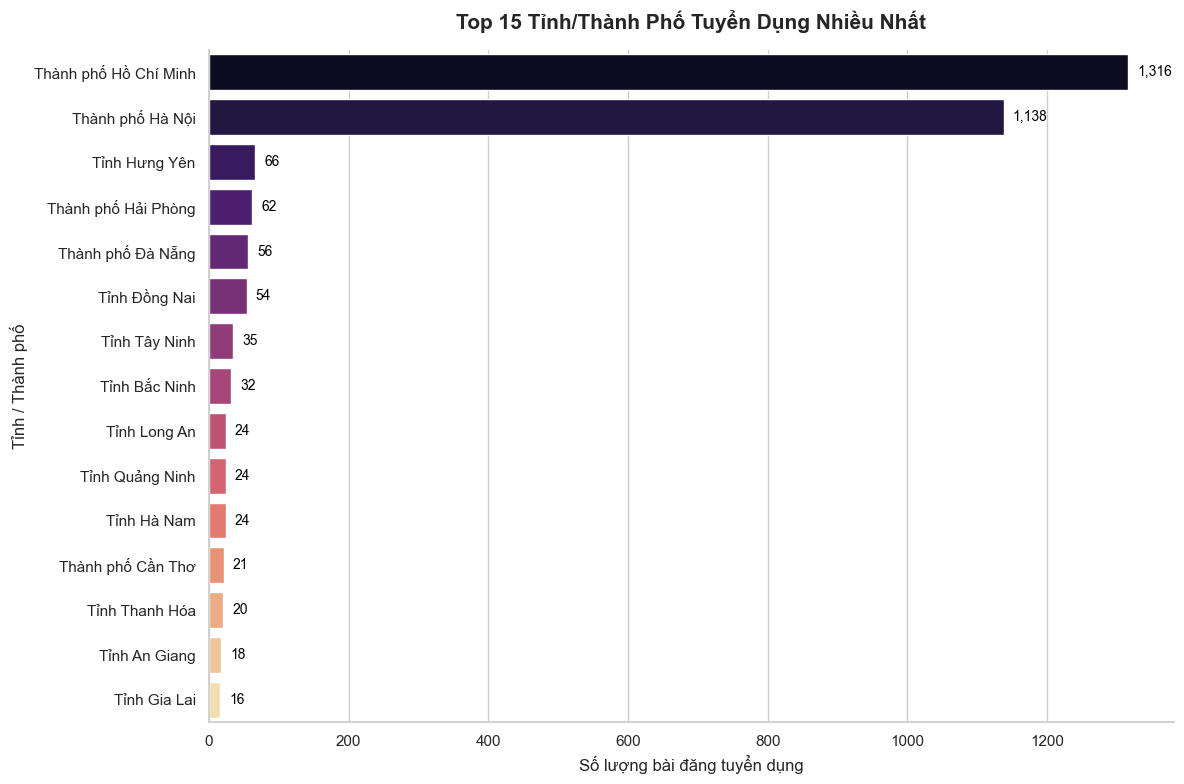

In [25]:
# Đếm tần suất
region_counts = s_regions.value_counts()

# Lấy Top 15 tỉnh/thành phố xuất hiện nhiều nhất để biểu đồ không bị quá dày
top_regions = region_counts.head(15)

# 2. Thiết lập và vẽ biểu đồ
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

# Vẽ biểu đồ thanh ngang
ax = sns.barplot(
    x=top_regions.values, 
    y=top_regions.index, 
    palette="magma" # Sử dụng dải màu magma trực quan
)

# Thêm số liệu trực tiếp lên từng cột
for i, v in enumerate(top_regions.values):
    ax.text(v + (top_regions.max() * 0.01), i, f"{v:,}", 
            color='black', va='center', fontweight='medium', fontsize=10)

# Định dạng tiêu đề và nhãn
plt.title('Top 15 Tỉnh/Thành Phố Tuyển Dụng Nhiều Nhất', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Số lượng bài đăng tuyển dụng', fontsize=12)
plt.ylabel('Tỉnh / Thành phố', fontsize=12)

# Bỏ đường viền trên và phải cho thoáng biểu đồ
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

### Experiences

In [32]:
# 1. Trích xuất dữ liệu và xử lý các giá trị trống (Không dropna)
s_exp = df['listing_response.experiences_str'].copy()

"""# Chuyển NaN thành chữ 'Trống / Chưa khai báo'
s_exp = s_exp.fillna('Trống / Chưa khai báo')

# Chuyển các chuỗi rỗng (như "", " ") thành 'Trống / Chưa khai báo'
s_exp = s_exp.replace(r'^\s*$', 'Trống / Chưa khai báo', regex=True)"""

# 2. Đếm tần suất và tính tỷ lệ (%)
exp_counts = s_exp.value_counts()
exp_rates = s_exp.value_counts(normalize=True) * 100

# 3. Đưa vào DataFrame để hiển thị bảng
df_exp_stats = pd.DataFrame({
    'Yêu cầu kinh nghiệm': exp_counts.index,
    'Số lượng bài đăng': exp_counts.values,
    'Tỷ lệ (%)': exp_rates.values
})

# In bảng Top 15
print("--- THỐNG KÊ YÊU CẦU KINH NGHIỆM---")
display(
    df_exp_stats.head(15).style
    .format({'Số lượng bài đăng': '{:,}', 'Tỷ lệ (%)': '{:.2f}%'})
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#264653'), ('color', 'white'), ('font-weight', 'bold')]},
        {'selector': 'td', 'props': [('text-align', 'left')]}
    ])
    .hide(axis="index")
)

--- THỐNG KÊ YÊU CẦU KINH NGHIỆM---


Yêu cầu kinh nghiệm,Số lượng bài đăng,Tỷ lệ (%)
1 năm,599,21.26%
Không yêu cầu,511,18.13%
2 năm,401,14.23%
3 năm,354,12.56%
5 năm,256,9.08%
Tất cả kinh nghiệm,82,2.91%
"1 năm, 2 năm",69,2.45%
"2 năm, 3 năm",64,2.27%
"3 năm, 5 năm",57,2.02%
06 tháng,54,1.92%


In [34]:
# 1. Thêm dấu ngoặc vuông [...] để biến scalar thành list
null_s_exp = pd.DataFrame({
    'Số lượng Null': [s_exp.isnull().sum()],
    'Tỷ lệ Null (%)': [(s_exp.isnull().sum() / len(s_exp) * 100).round(2)],
    'Số lượng Non-Null': [s_exp.notnull().sum()],
    'Kiểu dữ liệu': [s_exp.dtypes]
}, index=['experiences_str']) # Đặt tên dòng cho rõ ràng

# 2. Hiển thị bảng (Vì chỉ có 1 dòng nên không cần lọc/sắp xếp nữa)
display(
    null_s_exp.style.bar(subset=['Tỷ lệ Null (%)'], color='#ff6b6b', vmin=0, vmax=100) \
              .format({'Tỷ lệ Null (%)': '{:.2f}%'})
)

,Số lượng Null,Tỷ lệ Null (%),Số lượng Non-Null,Kiểu dữ liệu
experiences_str,1,0.04%,2818,object


##### Biểu đồ yêu cầu kinh nghiệm

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_18692\1823266658.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=top_15_exp.values, y=top_15_exp.index, palette=colors)


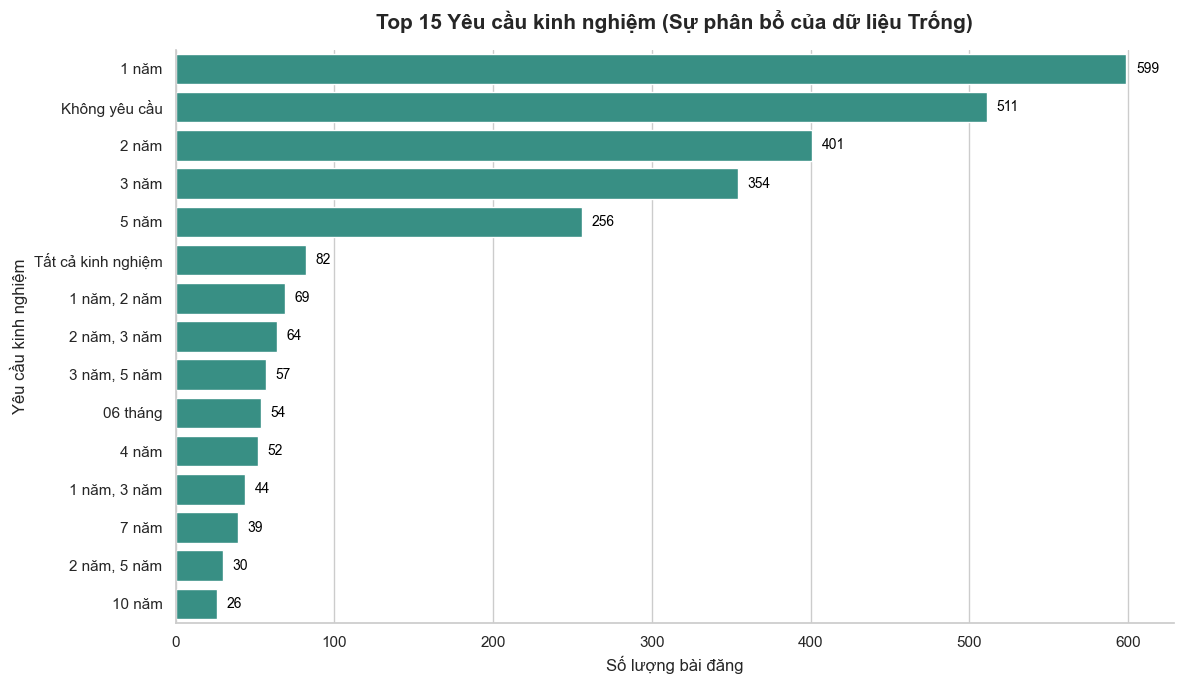

In [ ]:
# Vẽ biểu đồ trực quan (Làm nổi bật cột Dữ liệu trống)
plt.figure(figsize=(12, 7))
top_15_exp = exp_counts.head(15)

# Đặt màu đỏ cam cho cột "Trống / Chưa khai báo" để dễ nhận diện, các cột khác màu xanh
colors = ['#e76f51' if 'Trống' in str(idx) else '#2a9d8f' for idx in top_15_exp.index]

ax = sns.barplot(x=top_15_exp.values, y=top_15_exp.index, palette=colors)

# Thêm nhãn số lượng hiển thị ngay trên biểu đồ
for i, v in enumerate(top_15_exp.values):
    ax.text(v + (top_15_exp.max() * 0.01), i, f"{v:,}", color='black', va='center', fontsize=10)

plt.title('Top 15 Yêu cầu kinh nghiệm', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Số lượng bài đăng', fontsize=12)
plt.ylabel('Yêu cầu kinh nghiệm', fontsize=12)
sns.despine(right=True, top=True)

plt.tight_layout()
plt.show()

### Job levels   

In [39]:
# 1. Trích xuất, loại bỏ dữ liệu rỗng và "trải phẳng" mảng (explode)
s_levels = df['listing_response.job_levels_arr'].dropna().explode()

# Ép kiểu về chuỗi (string) và xóa khoảng trắng thừa ở hai đầu
s_levels = s_levels.astype(str).str.strip()

# 2. Đếm số lượng và tính tỷ lệ phần trăm
level_counts = s_levels.value_counts()
level_rates = s_levels.value_counts(normalize=True) * 100

# 3. Gom kết quả vào một DataFrame
df_levels = pd.DataFrame({
    'Cấp bậc công việc': level_counts.index,
    'Số lượng bài đăng': level_counts.values,
    'Tỷ lệ (%)': level_rates.values
})

# 4. Hiển thị bảng dạng trực quan có thanh bar chart thu nhỏ
print(f"--- THỐNG KÊ CẤP BẬC CÔNG VIỆC ---")
display(
    df_levels.style
    .format({
        'Số lượng bài đăng': '{:,}', 
        'Tỷ lệ (%)': '{:.2f}%'
    })
    # Vẽ thanh màu nền (bar) ở cột Tỷ lệ để dễ quan sát độ chênh lệch
    .bar(subset=['Tỷ lệ (%)'], color='#f4a261', vmin=0, vmax=100)
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#264653'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('padding', '8px')]},
        {'selector': 'tr:nth-child(even)', 'props': [('background-color', "#111010")]},
        {'selector': 'tr:hover', 'props': [('background-color', '#e0e0e0')]}
    ])
    .hide(axis="index")
)

--- THỐNG KÊ CẤP BẬC CÔNG VIỆC ---


Cấp bậc công việc,Số lượng bài đăng,Tỷ lệ (%)
Nhân viên,824,27.28%
Chuyên viên,682,22.58%
Chuyên viên cấp cao,648,21.45%
Trưởng nhóm,200,6.62%
Tất cả cấp bậc,197,6.52%
Trưởng phòng,192,6.36%
Giám đốc,141,4.67%
Thực tập,99,3.28%
Phó phòng,21,0.70%
Mới tốt nghiệp,11,0.36%


In [46]:
df_null_job_level = df['listing_response.job_levels_arr'].copy()
# 1. Thêm dấu ngoặc vuông [...] để biến scalar thành list
null_job_level = pd.DataFrame({
    'Số lượng Null': [df_null_job_level.isnull().sum()],
    'Tỷ lệ Null (%)': [(df_null_job_level.isnull().sum() / len(df_null_job_level) * 100).round(2)],
    'Số lượng Non-Null': [df_null_job_level.notnull().sum()],
    'Kiểu dữ liệu': [df_null_job_level.dtypes]
}, index=['job_levels']) # Đặt tên dòng cho rõ ràng

# 2. Hiển thị bảng (Vì chỉ có 1 dòng nên không cần lọc/sắp xếp nữa)
display(
    null_job_level.style.bar(subset=['Tỷ lệ Null (%)'], color='#ff6b6b', vmin=0, vmax=100) \
              .format({'Tỷ lệ Null (%)': '{:.2f}%'}))

,Số lượng Null,Tỷ lệ Null (%),Số lượng Non-Null,Kiểu dữ liệu
job_levels,0,0.00%,2819,object


##### Biểu đồ công việc được tuyển dụng nhều nhất

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_18692\2472971448.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


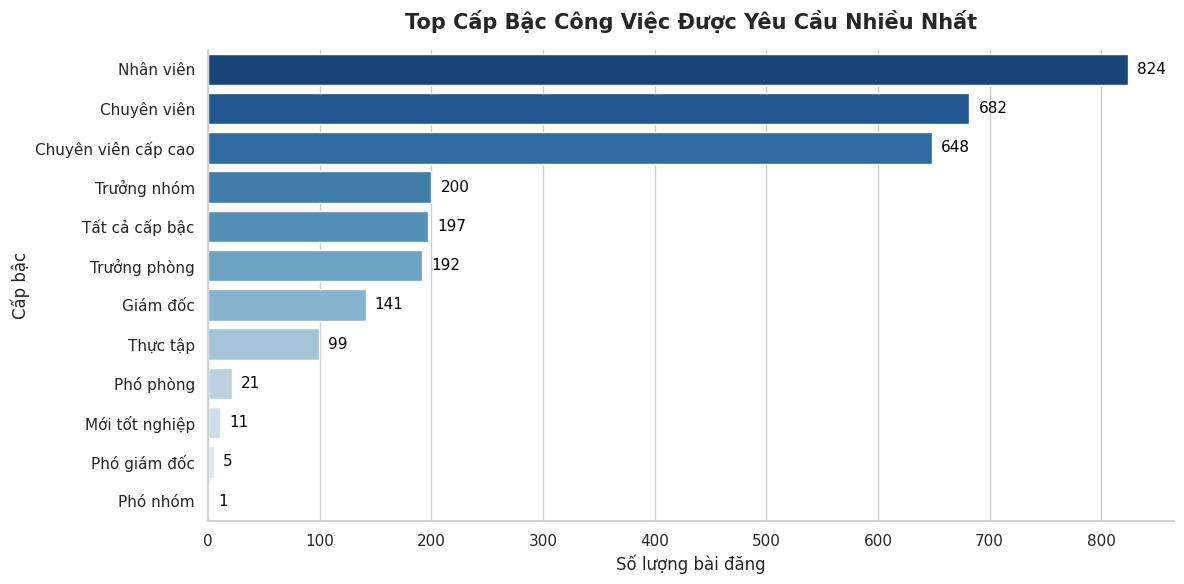

In [43]:
# Lấy Top 10 cấp bậc phổ biến nhất (nếu có nhiều hơn)
top_levels = level_counts.head(20)

# 2. Thiết lập kích thước và style biểu đồ
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Vẽ biểu đồ thanh ngang
ax = sns.barplot(
    x=top_levels.values, 
    y=top_levels.index, 
    palette="Blues_r"  # Dải màu xanh dương đậm nhạt theo thứ hạng
)

# 3. Thêm số lượng trực tiếp lên từng cột
for i, v in enumerate(top_levels.values):
    # Căn lề số lượng cách đầu cột một chút (1% của giá trị max) để không bị dính sát
    ax.text(v + (top_levels.max() * 0.01), i, f"{v:,}", 
            color='black', va='center', fontweight='medium', fontsize=11)

# 4. Định dạng tiêu đề và trục
plt.title('Top Cấp Bậc Công Việc Được Yêu Cầu Nhiều Nhất', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Số lượng bài đăng', fontsize=12)
plt.ylabel('Cấp bậc', fontsize=12)

# Xóa bỏ các đường viền bên trên và bên phải cho biểu đồ thoáng hơn
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

### Job types

In [45]:
# 1. Trích xuất dữ liệu và điền các giá trị Null
s_type = df['listing_response.job_types_str'].copy()
"""s_type = s_type.fillna('Trống / Chưa khai báo')"""

# 2. Ép kiểu chuỗi, tách các giá trị (nếu có dấu phẩy) và trải phẳng
# (Phòng trường hợp data ghi "Trực tiếp, Từ xa")
s_type = s_type.astype(str).str.split(',').explode()

# Cắt bỏ khoảng trắng thừa ở 2 đầu
s_type = s_type.str.strip()
"""s_type = s_type.replace(r'^\s*$', 'Trống / Chưa khai báo', regex=True)"""

# 3. Đếm số lượng và tính tỷ lệ phần trăm
type_counts = s_type.value_counts()
type_rates = s_type.value_counts(normalize=True) * 100

# 4. Gom kết quả vào một DataFrame
df_types = pd.DataFrame({
    'Hình thức làm việc': type_counts.index,
    'Số lượng bài đăng': type_counts.values,
    'Tỷ lệ (%)': type_rates.values
})

# 5. Hiển thị bảng với thanh Bar Chart thu nhỏ
print(f"--- THỐNG KÊ HÌNH THỨC LÀM VIỆC ---")
display(
    df_types.style
    .format({
        'Số lượng bài đăng': '{:,}', 
        'Tỷ lệ (%)': '{:.2f}%'
    })
    # Vẽ thanh màu nền biểu thị tỷ lệ % (dùng màu xanh lá mạ)
    .bar(subset=['Tỷ lệ (%)'], color='#2a9d8f', vmin=0, vmax=100)
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', "#0a2dac"), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('padding', '8px')]},
        {'selector': 'tr:nth-child(even)', 'props': [('background-color', "#1A0606")]},
        {'selector': 'tr:hover', 'props': [('background-color', '#e0e0e0')]}
    ])
    .hide(axis="index")
)

--- THỐNG KÊ HÌNH THỨC LÀM VIỆC ---


Hình thức làm việc,Số lượng bài đăng,Tỷ lệ (%)
Trực tiếp,"2,796",98.87%
Từ xa,13,0.46%
Linh hoạt,12,0.42%
Nước ngoài,5,0.18%
None,2,0.07%


In [47]:
df_null_job_types = df['listing_response.job_levels_arr'].copy()
# 1. Thêm dấu ngoặc vuông [...] để biến scalar thành list
null_job_level = pd.DataFrame({
    'Số lượng Null': [df_null_job_types.isnull().sum()],
    'Tỷ lệ Null (%)': [(df_null_job_types.isnull().sum() / len(df_null_job_types) * 100).round(2)],
    'Số lượng Non-Null': [df_null_job_types.notnull().sum()],
    'Kiểu dữ liệu': [df_null_job_types.dtypes]
}, index=['job_types']) # Đặt tên dòng cho rõ ràng

# 2. Hiển thị bảng (Vì chỉ có 1 dòng nên không cần lọc/sắp xếp nữa)
display(
    null_job_level.style.bar(subset=['Tỷ lệ Null (%)'], color='#ff6b6b', vmin=0, vmax=100) \
              .format({'Tỷ lệ Null (%)': '{:.2f}%'}))

,Số lượng Null,Tỷ lệ Null (%),Số lượng Non-Null,Kiểu dữ liệu
job_types,0,0.00%,2819,object


##### Biểu đồ hình thức làm việc

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_18692\949313471.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


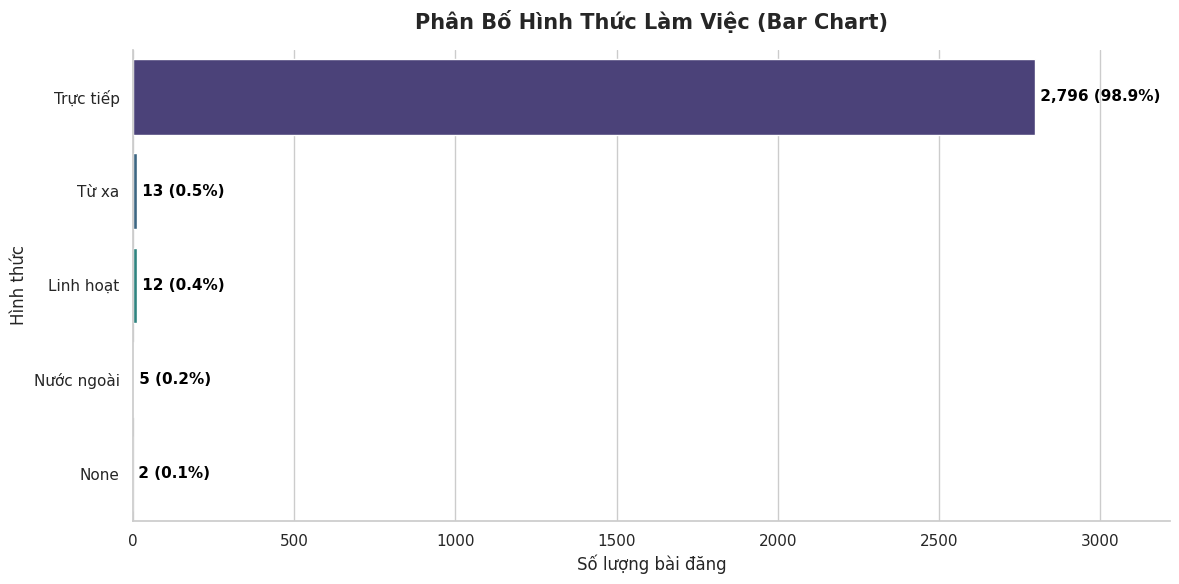

In [49]:
# Đếm tần suất và tính tổng
type_counts = s_type.value_counts()
total_items = type_counts.sum()

# 2. Thiết lập biểu đồ
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Vẽ biểu đồ thanh ngang
ax = sns.barplot(
    x=type_counts.values, 
    y=type_counts.index, 
    palette="viridis"
)

# 3. Ghi nhãn số lượng và tỷ lệ % ngay đuôi mỗi thanh Bar
for i, v in enumerate(type_counts.values):
    # Tính phần trăm cho từng nhóm
    pct = (v / total_items) * 100
    
    # In ra chuỗi định dạng: "Số lượng (Tỷ lệ %)"
    label_text = f" {v:,} ({pct:.1f}%)"
    
    # Đặt text cách đuôi thanh bar một chút
    ax.text(v, i, label_text, color='black', va='center', fontweight='bold', fontsize=11)

# Mở rộng trục X thêm 15% không gian trống để chữ (labels) không bị cắt lề phải
ax.set_xlim(0, type_counts.max() * 1.15)

# 4. Tiêu đề và định dạng trục
plt.title('Phân Bố Hình Thức Làm Việc (Bar Chart)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Số lượng bài đăng', fontsize=12)
plt.ylabel('Hình thức', fontsize=12)

# Bỏ viền trên và phải cho biểu đồ thanh thoát
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()